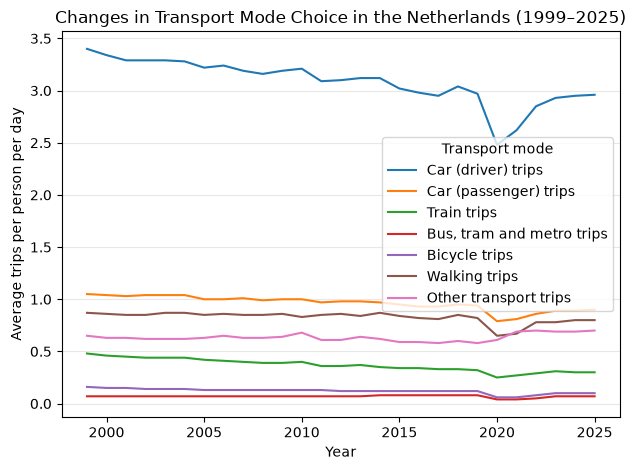

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read the dataset
df = pd.read_csv(
    "Data_age_research/mobilieitstrend per rit, vervoerwijzen, reismotief, leeftijd en geslacht.csv",
    sep=";",
    skiprows=5,
    header=[0, 1, 2, 3],
    decimal=",",
    na_values=[".", ""]
)

# Select all transport modes for the total population
# and all travel purposes
columns = [
    col for col in df.columns
    if col[0] not in ["Perioden", "Totaal"]
    and col[1] == "Totaal"
    and col[2] == "Totaal"
]

# Extract the years
years = pd.to_numeric(
    df.iloc[:, 0].astype(str).str.replace("*", "", regex=False),
    errors="coerce"
)

# Keep the years 1999–2025
mask = years.between(1999, 2025)

labels = [
    "Car (driver) trips",
    "Car (passenger) trips",
    "Train trips",
    "Bus, tram and metro trips",
    "Bicycle trips",
    "Walking trips",
    "Other transport trips"
]

for i, col in enumerate(columns[:-1]): #exclude the last column which is "Totaal"
    plt.plot(
        years[mask],
        df.loc[mask, col],
        label=labels[i]
    )



plt.xlabel("Year")
plt.ylabel("Average trips per person per day")
plt.title("Changes in Transport Mode Choice in the Netherlands (1999–2025)")
plt.legend(title="Transport mode")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
def calculate_shares(data):
    """
    Calculate the percentage share of each transport mode per year.
    """
    total_trips_per_year = data.sum(axis=1)
    shares = data.div(total_trips_per_year, axis=0) * 100

    return shares

In [53]:
shares = calculate_shares(df.loc[mask, columns[:-1]])  # Exclude the last column which is "Totaal"

# Give columns clear names
shares.columns = labels
shares.index.name = "Year"
shares = shares.reset_index()

# Round percentages
shares.iloc[:, 1:] = shares.iloc[:, 1:].round(2)

# Display the clean table
display(shares)

,Year,Car (driver) trips,Car (passenger) trips,Train trips,"Bus, tram and metro trips",Bicycle trips,Walking trips,Other transport trips
0,0,50.90,15.72,7.19,1.05,2.40,13.02,9.73
1,1,50.99,15.88,7.02,1.07,2.29,13.13,9.62
2,2,50.85,15.92,6.96,1.08,2.32,13.14,9.74
3,3,51.01,16.12,6.82,1.09,2.17,13.18,9.61
4,4,50.85,16.07,6.80,1.08,2.16,13.45,9.58
5,5,50.77,16.10,6.81,1.08,2.17,13.47,9.60
6,6,50.95,15.82,6.65,1.11,2.06,13.45,9.97
7,7,50.94,15.72,6.45,1.10,2.04,13.52,10.22
8,8,50.80,16.08,6.37,1.11,2.07,13.54,10.03
9,9,50.80,15.92,6.27,1.13,2.09,13.67,10.13


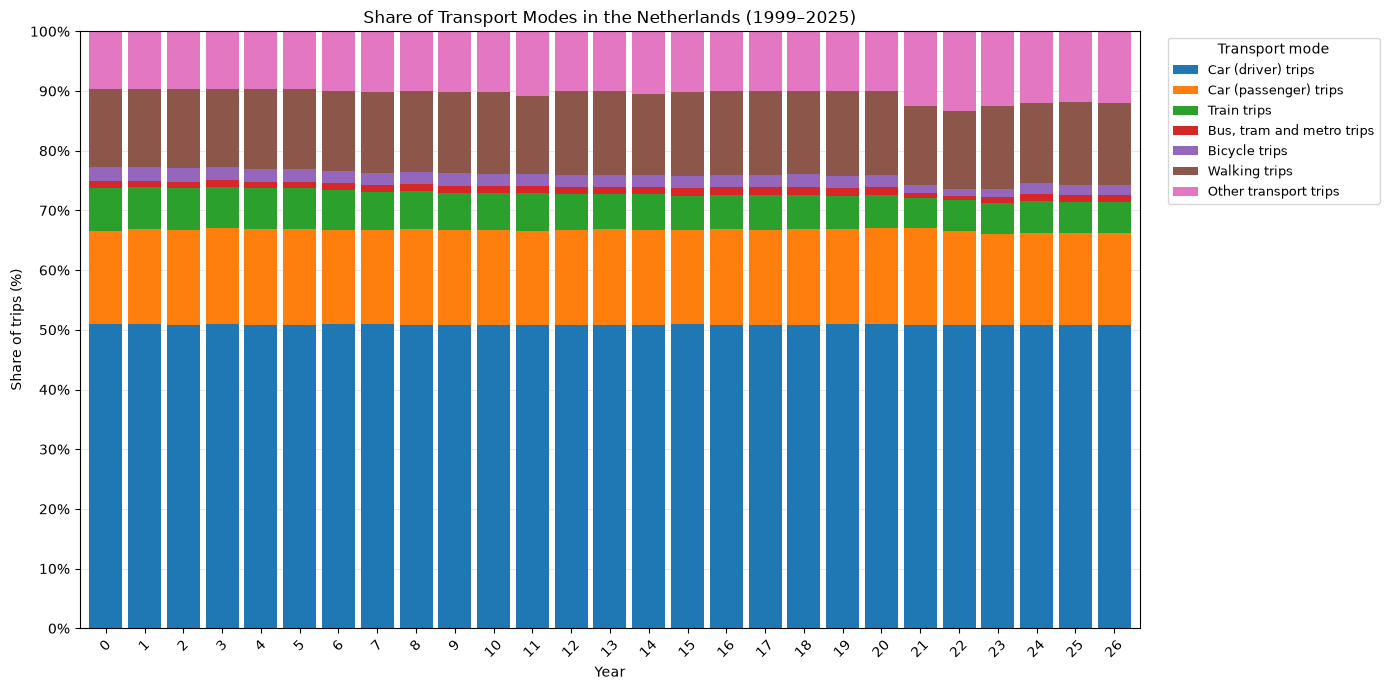

In [56]:
# Create a 100% stacked bar chart
ax = shares.set_index("Year").plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    width=0.85
)
#set titles
ax.set_xlabel("Year")
ax.set_ylabel("Share of trips (%)")
ax.set_title("Share of Transport Modes in the Netherlands (1999–2025)")

# Set y-axis from 0% to 100%, in steps of 10%
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_yticklabels([f"{i}%" for i in range(0, 101, 10)])

# Improve legend
ax.legend(
    title="Transport mode",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

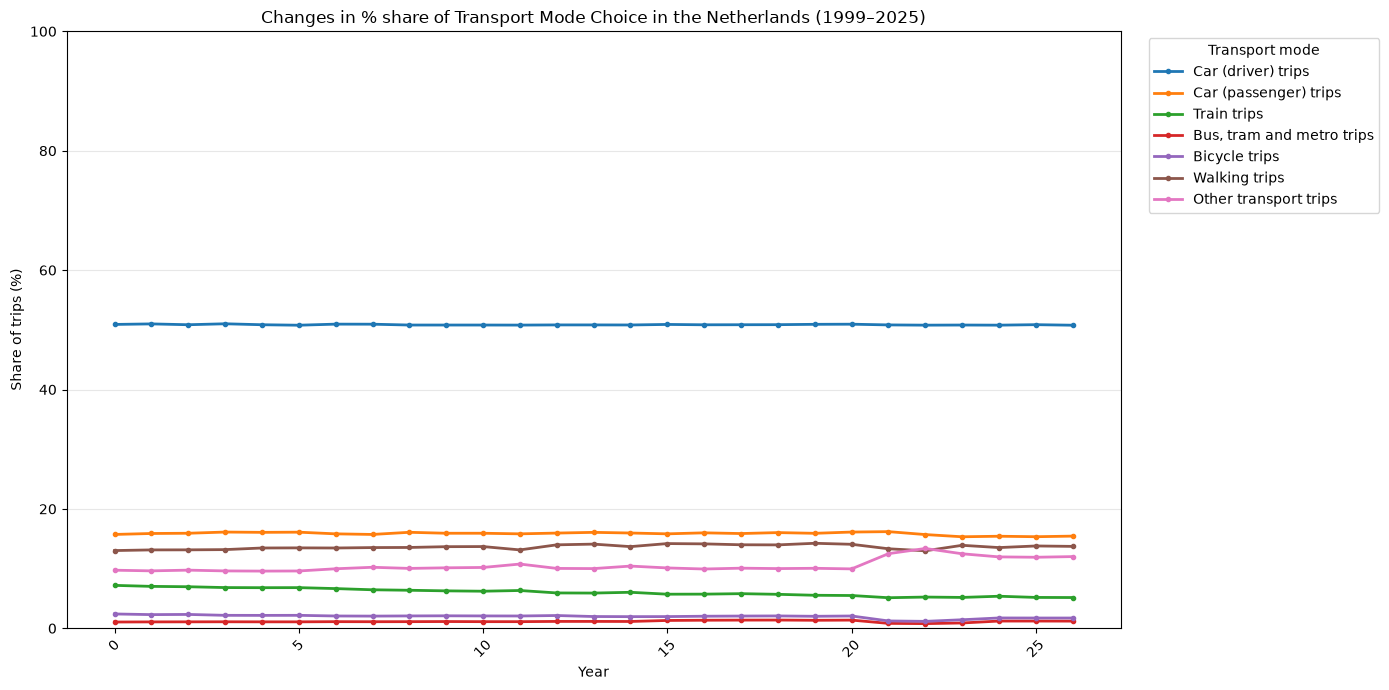

In [62]:

ax = shares.set_index("Year").plot(
    kind="line",
    figsize=(14, 7),
    marker="o",
    linewidth=2,
    markersize=3
)

ax.set_xlabel("Year")
ax.set_ylabel("Share of trips (%)")
ax.set_title("Changes in % share of Transport Mode Choice in the Netherlands (1999–2025)")
ax.set_ylim(0, 100)
ax.legend(
    title="Transport mode",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
